### Inference and Ensembling with Hough Transform Enhancement
After training, you need to use the two models to find the encroachment zones. This script shows how to load an image, apply Hough transform to enhance power line visibility, get predictions from both models, and combine them. The Hough transform helps detect power lines that may be obscured by vegetation overlay.

In [1]:
import torch
import cv2
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt

In [2]:
# --- Hough Transform Functions for Power Line Enhancement ---

def apply_hough_transform(image_rgb, rho=1, theta_resolution=180, threshold=50, 
                         min_line_length=30, max_line_gap=10, line_thickness=2):
    """
    Apply Hough transform to detect and enhance linear features (power lines).
    
    Args:
        image_rgb (np.array): Input RGB image
        rho (int): Distance resolution in pixels
        theta_resolution (int): Angle resolution (divides pi by this value)
        threshold (int): Minimum votes for line detection
        min_line_length (int): Minimum line length
        max_line_gap (int): Maximum gap between line segments
        line_thickness (int): Thickness for drawing detected lines
    
    Returns:
        tuple: (enhanced_image, hough_lines_mask, detected_lines)
    """
    # Convert to grayscale for line detection
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    
    # Apply Gaussian blur to reduce noise
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    
    # Edge detection using Canny
    edges = cv2.Canny(blurred, 50, 150, apertureSize=3)
    
    # Apply Hough Line Transform
    theta = np.pi / theta_resolution
    lines = cv2.HoughLinesP(edges, rho, theta, threshold, 
                           minLineLength=min_line_length, 
                           maxLineGap=max_line_gap)
    
    # Create masks for visualization
    hough_lines_mask = np.zeros_like(gray)
    enhanced_image = image_rgb.copy()
    
    detected_lines = []
    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = line[0]
            detected_lines.append((x1, y1, x2, y2))
            
            # Draw lines on the mask
            cv2.line(hough_lines_mask, (x1, y1), (x2, y2), 255, line_thickness)
            
            # Enhance lines in the original image (make them more visible)
            cv2.line(enhanced_image, (x1, y1), (x2, y2), (255, 255, 0), line_thickness)
    
    return enhanced_image, hough_lines_mask, detected_lines

def create_power_line_enhancement_mask(image_rgb, detected_lines, enhancement_strength=0.3):
    """
    Create an enhancement mask that highlights detected power lines.
    
    Args:
        image_rgb (np.array): Original RGB image
        detected_lines (list): List of detected line coordinates
        enhancement_strength (float): Strength of enhancement (0.0 to 1.0)
    
    Returns:
        np.array: Enhanced RGB image with power lines highlighted
    """
    enhanced = image_rgb.copy().astype(np.float32)
    
    # Create line mask
    line_mask = np.zeros(image_rgb.shape[:2], dtype=np.uint8)
    
    if detected_lines:
        for x1, y1, x2, y2 in detected_lines:
            cv2.line(line_mask, (x1, y1), (x2, y2), 255, 3)
    
    # Apply Gaussian blur to create soft enhancement area
    line_mask_blurred = cv2.GaussianBlur(line_mask, (7, 7), 0)
    line_mask_normalized = line_mask_blurred.astype(np.float32) / 255.0
    
    # Enhance contrast along detected lines
    for c in range(3):  # For each RGB channel
        enhanced[:, :, c] = enhanced[:, :, c] + (line_mask_normalized * enhancement_strength * 255)
    
    # Clip values to valid range
    enhanced = np.clip(enhanced, 0, 255).astype(np.uint8)
    
    return enhanced

def preprocess_image_with_hough(image_rgb, apply_enhancement=True):
    """
    Preprocess image with Hough transform to enhance power line visibility.
    
    Args:
        image_rgb (np.array): Input RGB image
        apply_enhancement (bool): Whether to apply power line enhancement
    
    Returns:
        tuple: (enhanced_image, hough_mask, line_count, original_image)
    """
    original_image = image_rgb.copy()
    
    if apply_enhancement:
        # Apply Hough transform
        enhanced_img, hough_mask, detected_lines = apply_hough_transform(image_rgb)
        
        # Further enhance power lines
        final_enhanced = create_power_line_enhancement_mask(image_rgb, detected_lines)
        
        line_count = len(detected_lines) if detected_lines else 0
        
        return final_enhanced, hough_mask, line_count, original_image
    else:
        # Return original image without enhancement
        hough_mask = np.zeros(image_rgb.shape[:2], dtype=np.uint8)
        return original_image, hough_mask, 0, original_image

In [3]:
# --- Configuration ---
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
MODEL_VEG_PATH = '../models/vepl_vegetation_model.pth.tar'
MODEL_PL_PATH = '../models/vepl_powerline_model.pth.tar'
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 256

# --- Load Models ---
def load_model(path, model_class, encoder_name):
    model = model_class(
        encoder_name=encoder_name,
        encoder_weights=None, # No need for weights at inference
        in_channels=3,
        classes=1,
    ).to(DEVICE)
    checkpoint = torch.load(path, map_location=DEVICE)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    return model

veg_model = load_model(MODEL_VEG_PATH, smp.Unet, "vgg16")
pl_model = load_model(MODEL_PL_PATH, smp.DeepLabV3, "resnet34")

# --- Inference transform ---
transform = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    A.Normalize(mean=[0.0, 0.0, 0.0], std=[1.0, 1.0, 1.0], max_pixel_value=255.0),
    ToTensorV2(),
])

def predict_encroachment(image_path):
    # Load and preprocess image
    image_bgr = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    
    augmented = transform(image=image_rgb)
    input_tensor = augmented['image'].unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        # Get predictions
        pred_veg = torch.sigmoid(veg_model(input_tensor))
        pred_pl = torch.sigmoid(pl_model(input_tensor))
        
        # Threshold to get binary masks
        pred_veg = (pred_veg > 0.5).float().squeeze(0).squeeze(0).cpu().numpy()
        pred_pl = (pred_pl > 0.5).float().squeeze(0).squeeze(0).cpu().numpy()

    # --- Ensembling: Intersection ---
    # The encroachment is where both models predict a positive class
    encroachment_mask = np.logical_and(pred_veg, pred_pl).astype(np.uint8)

    # --- Visualization ---
    fig, axes = plt.subplots(2, 2, figsize=(12, 12))
    axes = axes.ravel()
    
    axes[0].imshow(image_rgb)
    axes[0].set_title("Original Image")
    axes[0].axis('off')
    
    axes[1].imshow(image_rgb)
    axes[1].imshow(pred_veg, cmap='viridis', alpha=0.5)
    axes[1].set_title("Vegetation Prediction")
    axes[1].axis('off')

    axes[2].imshow(image_rgb)
    axes[2].imshow(pred_pl, cmap='plasma', alpha=0.5)
    axes[2].set_title("Power Line Prediction")
    axes[2].axis('off')
    
    # Create a color mask for encroachment
    encroachment_viz = np.zeros_like(image_rgb)
    encroachment_viz[encroachment_mask == 1] = [255, 0, 0] # Red

    axes[3].imshow(image_rgb)
    axes[3].imshow(encroachment_viz, alpha=0.7)
    axes[3].set_title("Encroachment Zone (Red)")
    axes[3].axis('off')

    plt.tight_layout()
    plt.show()

Total images: 2447
Training images: 0 to 1956
Test images: 1957 to 2446
Test set size: 490
Selecting test images with both vegetation and power lines...
Filtering for images with both vegetation and power lines...
Found 23 test images with both classes
Selected images with class pixel counts:
  tile_002307.png: VEG=35,520, PL=131
  tile_002446.png: VEG=15,779, PL=395
  tile_002354.png: VEG=28,036, PL=358
  tile_002284.png: VEG=4,582, PL=595
Selected 4 test images with both classes
\n=== Running predictions WITH Hough Transform Enhancement ===
Creating Hough-enhanced visualization grid WITH Hough transform:
4 rows x 4 columns for 4 images
Processed tile_002307.png: LINES=238, VEG=0, PL=0, ENCROACH=0
Processed tile_002446.png: LINES=144, VEG=0, PL=0, ENCROACH=0
Processed tile_002354.png: LINES=169, VEG=27,705, PL=0, ENCROACH=0
Processed tile_002284.png: LINES=101, VEG=4,351, PL=0, ENCROACH=0


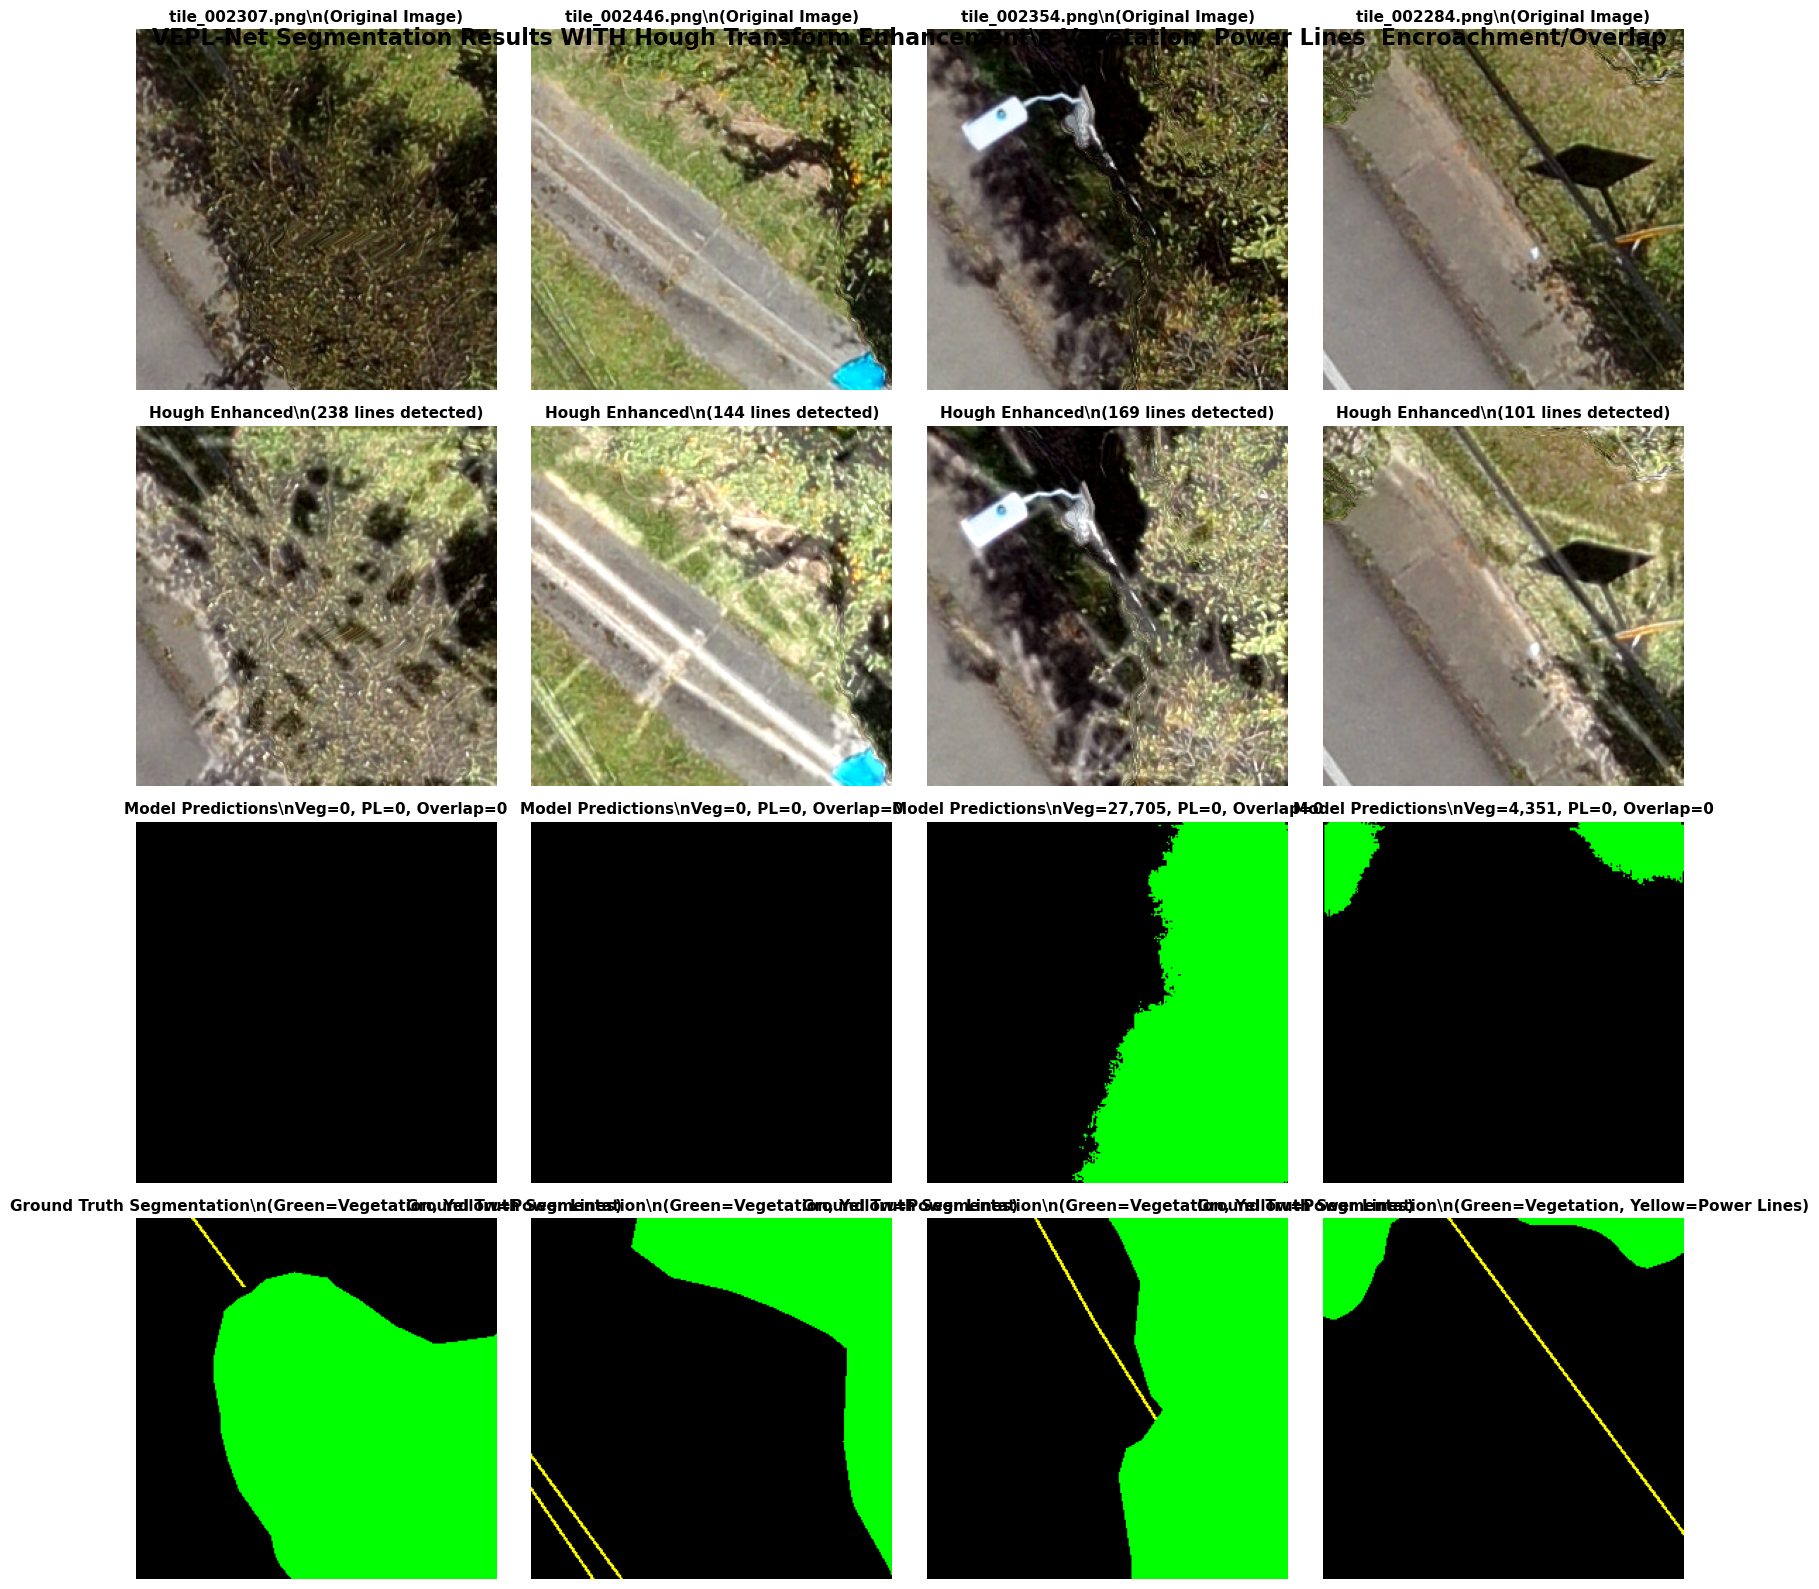

\n=== Running predictions WITHOUT Hough Transform Enhancement (for comparison) ===
Creating Hough-enhanced visualization grid WITHOUT Hough transform:
4 rows x 4 columns for 4 images
Processed tile_002307.png: LINES=0, VEG=52,819, PL=0, ENCROACH=0
Processed tile_002446.png: LINES=0, VEG=3,617, PL=0, ENCROACH=0
Processed tile_002354.png: LINES=0, VEG=30,067, PL=0, ENCROACH=0
Processed tile_002284.png: LINES=0, VEG=5,110, PL=0, ENCROACH=0


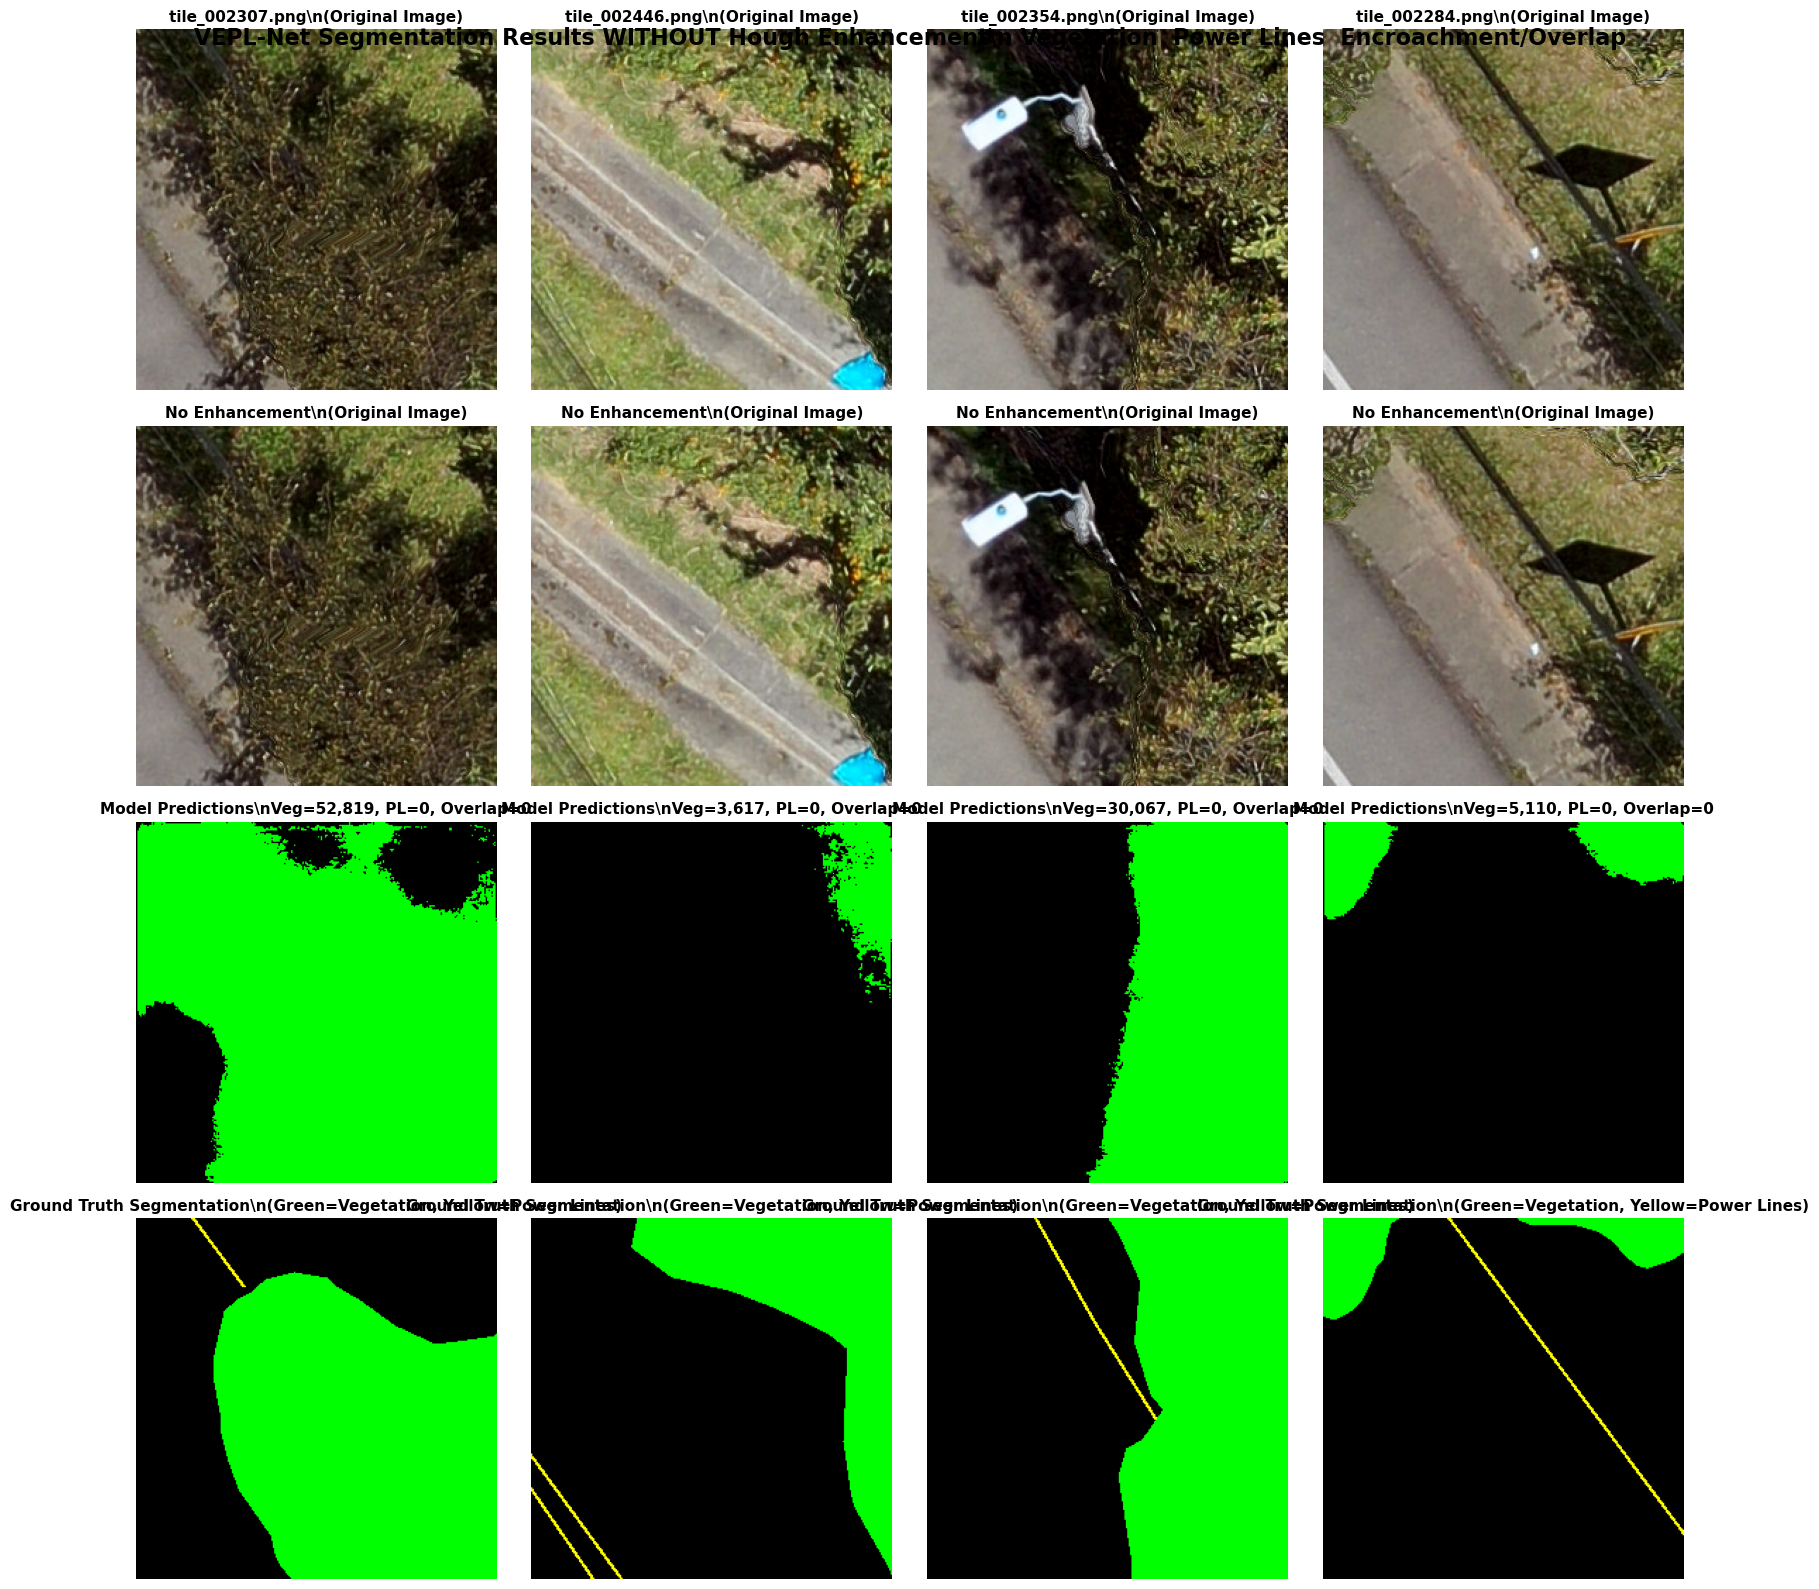

In [4]:
import os
import random

# Dataset configuration
TOTAL_IMAGES = 2447
TEST_RATIO = 0.2
DATA_DIR = '../processed_data'

# Calculate test set range (last 20% of images)
train_size = int(TOTAL_IMAGES * (1 - TEST_RATIO))
test_start_idx = train_size
test_end_idx = TOTAL_IMAGES - 1

print(f"Total images: {TOTAL_IMAGES}")
print(f"Training images: 0 to {train_size - 1}")
print(f"Test images: {test_start_idx} to {test_end_idx}")
print(f"Test set size: {test_end_idx - test_start_idx + 1}")

def has_both_classes(mask_path, veg_threshold=50, pl_threshold=10):
    """
    Check if a mask contains both vegetation and power lines.
    
    Args:
        mask_path (str): Path to mask file
        veg_threshold (int): Minimum vegetation pixels required
        pl_threshold (int): Minimum power line pixels required
    
    Returns:
        tuple: (has_both, veg_pixels, pl_pixels)
    """
    if not os.path.exists(mask_path):
        return False, 0, 0
    
    # Load mask
    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    if mask is None:
        return False, 0, 0
    
    # Convert BGR to RGB if needed
    if len(mask.shape) == 3:
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
    
    # Define class RGB values
    VEGETATION_RGB = (0, 255, 0)    # Green
    POWERLINE_RGB = (110, 110, 110) # Gray
    
    # Count pixels for each class using RGB values
    if len(mask.shape) == 3:
        vegetation_mask = np.all(mask == VEGETATION_RGB, axis=2)
        vegetation_pixels = np.sum(vegetation_mask)
        
        powerline_mask = np.all(mask == POWERLINE_RGB, axis=2)  
        powerline_pixels = np.sum(powerline_mask)
    else:
        # Fallback for grayscale masks
        vegetation_pixels = np.sum(mask == 255)  # Green -> ~255 in grayscale
        powerline_pixels = np.sum(mask == 110)   # Gray -> 110 in grayscale
    
    has_both = vegetation_pixels >= veg_threshold and powerline_pixels >= pl_threshold
    return has_both, vegetation_pixels, powerline_pixels

def get_random_test_images(num_images=8, require_both_classes=True):
    """
    Get random image paths from the test set, optionally filtering for images 
    that contain both vegetation and power lines.
    """
    test_indices = list(range(test_start_idx, test_end_idx + 1))
    
    if require_both_classes:
        print("Filtering for images with both vegetation and power lines...")
        valid_indices = []
        
        for idx in test_indices:
            mask_path = os.path.join(DATA_DIR, 'masks', f'tile_{idx:06d}.png')
            has_both, veg_px, pl_px = has_both_classes(mask_path)
            
            if has_both:
                valid_indices.append((idx, veg_px, pl_px))
        
        print(f"Found {len(valid_indices)} test images with both classes")
        
        if len(valid_indices) < num_images:
            print(f"Only {len(valid_indices)} images available with both classes")
            num_images = len(valid_indices)
        
        # FIXED: Use random selection instead of always taking the top images
        random.shuffle(valid_indices)  # Randomize the order
        selected_indices = [idx for idx, _, _ in valid_indices[:num_images]]
        
        print("Selected images with class pixel counts:")
        for i, (idx, veg_px, pl_px) in enumerate(valid_indices[:num_images]):
            print(f"  tile_{idx:06d}.png: VEG={veg_px:,}, PL={pl_px:,}")
    else:
        selected_indices = random.sample(test_indices, min(num_images, len(test_indices)))
    
    image_paths = []
    for idx in selected_indices:
        image_path = os.path.join(DATA_DIR, 'images', f'tile_{idx:06d}.png')
        if os.path.exists(image_path):
            image_paths.append(image_path)
        else:
            print(f"Warning: Image not found: {image_path}")
    
    return image_paths

def create_colored_segmentation(veg_mask, pl_mask, encroachment_mask, image_shape):
    """
    Create a colored segmentation visualization:
    - Vegetation: Green (0, 255, 0)
    - Power Lines: Yellow (255, 255, 0)  
    - Encroachment/Overlap: Red (255, 0, 0)
    """
    # Create RGB image
    colored_mask = np.zeros((image_shape[0], image_shape[1], 3), dtype=np.uint8)
    
    # Apply colors in order of priority (encroachment > power lines > vegetation)
    # Vegetation areas (green)
    vegetation_only = np.logical_and(veg_mask > 0.5, pl_mask <= 0.5)
    colored_mask[vegetation_only] = [0, 255, 0]  # Green
    
    # Power line areas (yellow)
    powerline_only = np.logical_and(pl_mask > 0.5, veg_mask <= 0.5)
    colored_mask[powerline_only] = [255, 255, 0]  # Yellow
    
    # Encroachment areas (red) - highest priority
    colored_mask[encroachment_mask > 0] = [255, 0, 0]  # Red
    
    return colored_mask

def predict_and_visualize_batch_with_hough(image_paths, use_hough_enhancement=True):
    """
    Predict encroachment with Hough transform enhancement and 4-row visualization:
    Row 1: Original image
    Row 2: Hough-enhanced image (with detected lines highlighted)
    Row 3: Model predictions (Green=Vegetation, Yellow=Power Lines, Red=Overlap)
    Row 4: Ground truth segmentation (same color scheme)
    """
    num_images = len(image_paths)
    if num_images == 0:
        print("No valid images found!")
        return
    
    # Layout: 4 rows per image (added Hough enhancement row)
    cols = min(4, num_images)  # Max 4 columns for readability
    rows_per_image = 4  # Extended to 4 rows
    total_rows = rows_per_image
    
    # If more than 4 images, create multiple rows of image sets
    if num_images > 4:
        sets = (num_images + 3) // 4  # Number of 4-image sets needed
        total_rows = rows_per_image * sets
        cols = 4
    
    enhancement_text = "WITH" if use_hough_enhancement else "WITHOUT"
    print(f"Creating Hough-enhanced visualization grid {enhancement_text} Hough transform:")
    print(f"{total_rows} rows x {cols} columns for {num_images} images")
    
    # Create the figure with proper size
    fig, axes = plt.subplots(total_rows, cols, figsize=(cols * 4, total_rows * 4))
    
    # Handle single image case
    if num_images == 1:
        axes = axes.reshape(-1, 1)
    elif total_rows == 4:  # Single row of images
        axes = axes.reshape(4, -1)
    
    for i, image_path in enumerate(image_paths):
        # Calculate position in grid
        set_idx = i // 4  # Which set of 4 images
        col = i % 4       # Column within the set
        row_offset = set_idx * rows_per_image
        
        try:
            # Load and preprocess image
            image_bgr = cv2.imread(image_path)
            if image_bgr is None:
                print(f"Could not load image: {image_path}")
                continue
                
            image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
            
            # Apply Hough transform preprocessing
            if use_hough_enhancement:
                enhanced_image, hough_mask, line_count, original_image = preprocess_image_with_hough(
                    image_rgb, apply_enhancement=True)
                processing_image = enhanced_image  # Use enhanced image for model prediction
            else:
                enhanced_image, hough_mask, line_count, original_image = preprocess_image_with_hough(
                    image_rgb, apply_enhancement=False)
                processing_image = original_image  # Use original image for model prediction
            
            # Load corresponding ground truth mask
            image_name = os.path.basename(image_path)
            mask_path = os.path.join(DATA_DIR, 'masks', image_name)
            
            # Process with model using enhanced/original image
            augmented = transform(image=processing_image)
            input_tensor = augmented['image'].unsqueeze(0).to(DEVICE)

            with torch.no_grad():
                # Get model predictions
                pred_veg = torch.sigmoid(veg_model(input_tensor))
                pred_pl = torch.sigmoid(pl_model(input_tensor))
                
                # Convert to numpy
                pred_veg_np = pred_veg.squeeze(0).squeeze(0).cpu().numpy()
                pred_pl_np = pred_pl.squeeze(0).squeeze(0).cpu().numpy()

            # Create encroachment mask (intersection)
            encroachment_mask = np.logical_and(pred_veg_np > 0.5, pred_pl_np > 0.5)
            
            # Create colored prediction visualization
            pred_colored = create_colored_segmentation(pred_veg_np, pred_pl_np, encroachment_mask, processing_image.shape)
            
            # Load and process ground truth mask
            gt_colored = np.zeros_like(image_rgb)
            if os.path.exists(mask_path):
                gt_mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
                if gt_mask is not None:
                    gt_mask = cv2.cvtColor(gt_mask, cv2.COLOR_BGR2RGB)
                    
                    # Create ground truth colored visualization
                    veg_gt = np.all(gt_mask == [0, 255, 0], axis=2)
                    pl_gt = np.all(gt_mask == [110, 110, 110], axis=2)
                    
                    gt_colored[veg_gt] = [0, 255, 0]    # Green for vegetation
                    gt_colored[pl_gt] = [255, 255, 0]   # Yellow for power lines
            
            # Calculate statistics
            veg_pixels = np.sum(pred_veg_np > 0.5)
            pl_pixels = np.sum(pred_pl_np > 0.5)  
            encroach_pixels = np.sum(encroachment_mask)
            
            # Row 1: Original image
            axes[row_offset + 0, col].imshow(original_image)
            axes[row_offset + 0, col].set_title(f"{image_name}\\n(Original Image)", fontsize=11, fontweight='bold')
            axes[row_offset + 0, col].axis('off')
            
            # Row 2: Hough-enhanced image
            hough_title = f"Hough Enhanced\\n({line_count} lines detected)" if use_hough_enhancement else "No Enhancement\\n(Original Image)"
            axes[row_offset + 1, col].imshow(enhanced_image)
            axes[row_offset + 1, col].set_title(hough_title, fontsize=11, fontweight='bold')
            axes[row_offset + 1, col].axis('off')
            
            # Row 3: Model predictions colored
            axes[row_offset + 2, col].imshow(pred_colored)
            axes[row_offset + 2, col].set_title(f"Model Predictions\\nVeg={veg_pixels:,}, PL={pl_pixels:,}, Overlap={encroach_pixels:,}", 
                                              fontsize=11, fontweight='bold')
            axes[row_offset + 2, col].axis('off')
            
            # Row 4: Ground truth colored
            axes[row_offset + 3, col].imshow(gt_colored)
            axes[row_offset + 3, col].set_title(f"Ground Truth Segmentation\\n(Green=Vegetation, Yellow=Power Lines)", 
                                              fontsize=11, fontweight='bold')
            axes[row_offset + 3, col].axis('off')
            
            print(f"Processed {image_name}: LINES={line_count}, VEG={veg_pixels:,}, PL={pl_pixels:,}, ENCROACH={encroach_pixels:,}")
            
        except Exception as e:
            print(f"Error processing {image_path}: {str(e)}")
            continue
    
    # Hide unused subplots properly
    total_subplots = total_rows * cols
    images_shown = min(num_images, total_subplots // 4)  # 4 rows per image
    
    for i in range(images_shown, total_subplots // 4):
        col = i % 4
        set_idx = i // 4
        row_offset = set_idx * rows_per_image
        
        for row in range(4):  # 4 rows per image
            if row_offset + row < total_rows:
                axes[row_offset + row, col].axis('off')
    
    plt.tight_layout()
    enhancement_status = "WITH Hough Transform Enhancement" if use_hough_enhancement else "WITHOUT Hough Enhancement"
    plt.suptitle(f'VEPL-Net Segmentation Results {enhancement_status}\\n Vegetation  Power Lines  Encroachment/Overlap', 
                 fontsize=16, fontweight='bold', y=0.98)
    plt.show()

# Wrapper function for backward compatibility
def predict_and_visualize_batch(image_paths, use_hough_enhancement=True):
    """
    Wrapper function that calls the Hough-enhanced visualization by default.
    
    Args:
        image_paths (list): List of image paths to process
        use_hough_enhancement (bool): Whether to apply Hough transform enhancement
    """
    return predict_and_visualize_batch_with_hough(image_paths, use_hough_enhancement)

# Get test images with both vegetation and power lines
print("Selecting test images with both vegetation and power lines...")
filtered_test_paths = get_random_test_images(num_images=4, require_both_classes=True)  # Reduced to 4 for better visualization
print(f"Selected {len(filtered_test_paths)} test images with both classes")

if filtered_test_paths:
    print("\\n=== Running predictions WITH Hough Transform Enhancement ===")
    predict_and_visualize_batch_with_hough(filtered_test_paths, use_hough_enhancement=True)
    
    print("\\n=== Running predictions WITHOUT Hough Transform Enhancement (for comparison) ===")
    predict_and_visualize_batch_with_hough(filtered_test_paths, use_hough_enhancement=False)
else:
    print("No test images found with both vegetation and power lines!")
    print("Falling back to random test images...")
    random_test_paths = get_random_test_images(num_images=4, require_both_classes=False)
    if random_test_paths:
        predict_and_visualize_batch_with_hough(random_test_paths, use_hough_enhancement=True)